This script showcases different types of hypothesis testing.

In [42]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

project_dir = Path.cwd()
data_dir = project_dir / 'Raw Data'
result_dict = {}

# Get data

In [43]:
# Get the raw data here:  
# https://www.kaggle.com/datasets/alinoranianesfahani/dataco-smart-supply-chain-for-big-data-analysis/code
    
# load single-store sales data
DataCoSupplyChainDataset = pd.read_csv(
    data_dir / 'DataCoSupplyChainDataset.csv',
    encoding='Latin-1',
    low_memory=False
)

In [44]:
df = DataCoSupplyChainDataset.copy()

numeric_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk",
    "Sales",
    "Order Item Quantity",
    "Order Item Discount"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

df = df.dropna(subset=numeric_columns)

# actual delivery time minus scheduled delivery time
# positive = late; negative = early
df["Delivery_Delay"] = (
    df["Days for shipping (real)"]
    - df["Days for shipment (scheduled)"]
)

# a binary indicator for whether the delivery was actually late
df["Actually_Late"] = (
    df["Delivery_Delay"] > 0
).astype(int)

# order_df

In [45]:
# keep one row per order for order-level delivery tests
# shipping duration is generally an order-level measure
order_df = df.drop_duplicates(
    subset=["Order Id"]
).copy()

# Hypothesis test function

In [46]:
ALPHA = 0.05

def report_test(
    name,
    h0,
    h1,
    statistic,
    p_value
):
    """
    print the results and interpretation of a hypothesis test

    arguments
        name
            descriptive name for the hypothesis test

        h0
            null hypothesis representing no difference
            effect or association

        h1
            alternative hypothesis representing a difference
            effect or association being investigated

        statistic
            calculated test statistic such as a t statistic
            z statistic f statistic or chi square statistic

        p_value
            probability under the null hypothesis of observing
            a test statistic at least as extreme as the one
            calculated from the sample
    """

    # significance level commonly set to 0.05
    # represents a 5 percent threshold for rejecting h0
    alpha = 0.05

    print("\n" + "=" * 70)

    # descriptive name of the test
    print(name)

    print("-" * 70)

    # display the hypotheses
    print(f"h0 {h0}")
    print(f"h1 {h1}")

    # display the calculated test statistic and p value
    print(f"test statistic {statistic:.4f}")
    print(f"p value {p_value:.6f}")

    # compare the p value against the significance level
    if p_value < alpha:

        # a sufficiently small p value provides evidence
        # against the null hypothesis
        print("decision reject h0")

        print(
            "interpretation there is statistically significant "
            "evidence against the null hypothesis"
        )

    else:

        # a large p value means there is insufficient
        # evidence to reject the null hypothesis
        print("decision fail to reject h0")

        print(
            "interpretation there is insufficient evidence "
            "against the null hypothesis"
        )

# Paired t-test
Tests whether the differences of the means between two related samples is significantly different from zero.

Question:  
Is actual delivery time significantly different from scheduled delivery time?

The test statistic measures how many standard errors the mean paired difference is from zero, calculated as mean difference divided by standard error.

Formula:  
t = mean_difference / (standard_deviation_of_differences / sqrt(n))

In [47]:
actual_days = order_df[
    "Days for shipping (real)"
]

scheduled_days = order_df[
    "Days for shipment (scheduled)"
]

## Paired t-test assumptions

1. Paired observations: Each observation in one sample is matched to an observation in the other sample.
2. Independence between pairs: The paired differences are independent of one another.
3. Normality: The distribution of paired differences is approximately normal, especially for small samples.  
4. Continuous outcome: The paired differences are measured on a continuous numerical scale.

The normality assumption applies to the differences, not to the two original samples individually.

Large samples (CLT): With a sufficiently large sample, the Central Limit Theorem allows the sampling distribution of the mean difference to be approximately normal, even when the differences themselves are not normally distributed.  


As sample size increases, the LLN (law of large numbers) says the sample mean converges to the population mean, while the CLT says the sampling distribution of sample means approaches a normal distribution under suitable conditions.

## Below...
Investigate the fourth assumption: normality of the differences.

### 1. Distribution of paired differences

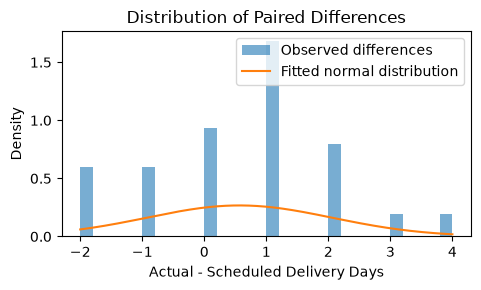

Paired differences contain outliers, as shown in the two tails.


In [48]:
# calculate paired differences
differences = (actual_days - scheduled_days).dropna()

# fit a normal distribution using the sample mean and std
mean_diff = differences.mean()
std_diff = differences.std(ddof=1)

x = np.linspace(
    differences.min(),
    differences.max(),
    1000
)

# plot histogram and fitted normal curve
plt.figure(figsize=(5, 3))

plt.hist(
    differences,
    bins=30,
    density=True,
    alpha=0.6,
    label="Observed differences"
)

plt.plot(
    x,
    stats.norm.pdf(x, mean_diff, std_diff),
    label="Fitted normal distribution"
)

plt.title("Distribution of Paired Differences")
plt.xlabel("Actual - Scheduled Delivery Days")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

print("Paired differences contain outliers, as shown in the two tails.")

In [49]:
differences.describe(percentiles=np.arange(0,1.05,0.05))

count    65752.000000
mean         0.566675
std          1.492009
min         -2.000000
0%          -2.000000
5%          -2.000000
10%         -2.000000
15%         -1.000000
20%         -1.000000
25%          0.000000
30%          0.000000
35%          0.000000
40%          0.000000
45%          1.000000
50%          1.000000
55%          1.000000
60%          1.000000
65%          1.000000
70%          1.000000
75%          1.000000
80%          2.000000
85%          2.000000
90%          2.000000
95%          3.000000
100%         4.000000
max          4.000000
dtype: float64

### 2. Q-Q plot
A quantile-quantile plot compares the observed data against what's expected from a normal distribution.

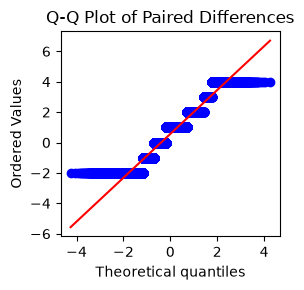

Those same outliers appear on either end of the q-q plot.


In [50]:
# qq plot of paired differences
plt.figure(figsize=(3, 3))

stats.probplot(
    differences,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot of Paired Differences")
plt.tight_layout()
plt.show()
print('Those same outliers appear on either end of the q-q plot.')

In [51]:
# d'agostino-pearson normality test
stat, p_value = stats.normaltest(differences)

print("D'Agostino-Pearson statistic:", stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Evidence against normality")
else:
    print("Insufficient evidence against normality")

D'Agostino-Pearson statistic: 330.6552616013321
P-value: 1.5816931621958704e-72
Evidence against normality


### Next steps
The paired t-test may still be appropriate due to the size of out N and the CLT/LLN, but we need to investigate the outliers; they could be real of just noise.  
Outliers affect the standard error which affects the test statistic.  
For this example, we'll go ahead with the paired t-test.

In [52]:
t_stat, p_value = stats.ttest_rel(
    actual_days,
    scheduled_days
)

report_test(
    name="1. Paired T-Test: Actual vs Scheduled Delivery",
    h0="Mean actual delivery time equals mean scheduled time",
    h1="Mean actual delivery time differs from scheduled time",
    statistic=t_stat,
    p_value=p_value
)

print(f"Mean actual days: {actual_days.mean():.2f}")
print(f"Mean scheduled days: {scheduled_days.mean():.2f}")
print(
    f"Mean delay: "
    f"{(actual_days - scheduled_days).mean():.2f} days"
)


1. Paired T-Test: Actual vs Scheduled Delivery
----------------------------------------------------------------------
h0 Mean actual delivery time equals mean scheduled time
h1 Mean actual delivery time differs from scheduled time
test statistic 97.3906
p value 0.000000
decision reject h0
interpretation there is statistically significant evidence against the null hypothesis
Mean actual days: 3.50
Mean scheduled days: 2.93
Mean delay: 0.57 days


## Paired t-test manual calcs
Another way to get the same answer as above, for reference.

In [53]:
# calculate the diffs
differences = actual_days - scheduled_days

# take the mean, get the std, get n
mean_difference = differences.mean()
std_difference = differences.std(ddof=1)
n = len(differences)
se = std_difference/np.sqrt(n)

# t statistic = mean of paired differences / standard error of differences
t_stat = mean_difference / (std_difference / np.sqrt(n))

print(t_stat)

97.39057436147986


## Paired t-test confidence intervals
A 95% confidence interval gives a range of plausible values for the true population mean difference between actual and scheduled delivery times.

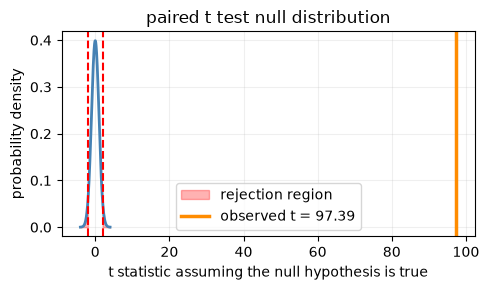

observed t statistic 97.39057436147986
p value 0.0

Observe how far outside the distribution our value is. This is strong evidence to reject the null.


In [54]:
# calculate the observed t statistic
t_stat = mean_difference / se

# create the null t distribution
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df=n - 1)

# calculate the two tailed critical values
critical_t = stats.t.ppf(0.975, df=n - 1)

fig, ax = plt.subplots(figsize=(5, 3))

# plot the null distribution
ax.plot(x, y, color="steelblue", linewidth=2)

# shade the rejection regions
ax.fill_between(
    x, y, where=(x <= -critical_t),
    color="red", alpha=0.3, label="rejection region"
)
ax.fill_between(
    x, y, where=(x >= critical_t),
    color="red", alpha=0.3
)

# mark the observed t statistic
ax.axvline(
    t_stat, color="darkorange", linewidth=2.5,
    label=f"observed t = {t_stat:.2f}"
)

# mark the critical values
ax.axvline(-critical_t, color="red", linestyle="--")
ax.axvline(critical_t, color="red", linestyle="--")

ax.set_title("paired t test null distribution")
ax.set_xlabel("t statistic assuming the null hypothesis is true")
ax.set_ylabel("probability density")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("observed t statistic", t_stat)
print("p value", stats.t.sf(abs(t_stat), df=n - 1) * 2)
print('\nObserve how far outside the distribution our value is. This is strong evidence to reject the null.')

## Explore: failure to reject the null
An illustration of what failing to reject the null would look like, for reference.

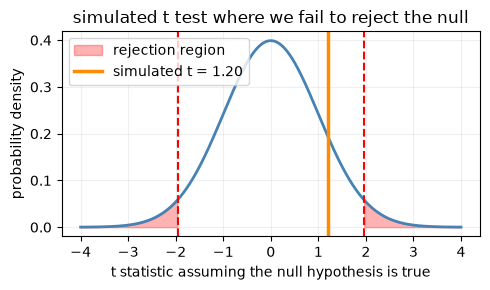

simulated t statistic 1.2
simulated p value 0.2301436641376733
fail to reject the null hypothesis


In [55]:
# simulate a t statistic inside the non-rejection region
simulated_t = 1.2

# create the null t distribution
x = np.linspace(-4, 4, 1000)
y = stats.t.pdf(x, df=n - 1)

# critical values for a two-tailed test at alpha 0.05
critical_t = stats.t.ppf(0.975, df=n - 1)

fig, ax = plt.subplots(figsize=(5, 3))

# plot the null distribution
ax.plot(x, y, color="steelblue", linewidth=2)

# shade the rejection regions
ax.fill_between(
    x, y, where=(x <= -critical_t),
    color="red", alpha=0.3, label="rejection region"
)
ax.fill_between(
    x, y, where=(x >= critical_t),
    color="red", alpha=0.3
)

# mark the simulated observed t statistic
ax.axvline(
    simulated_t,
    color="darkorange",
    linewidth=2.5,
    label=f"simulated t = {simulated_t:.2f}"
)

# mark the critical values
ax.axvline(-critical_t, color="red", linestyle="--")
ax.axvline(critical_t, color="red", linestyle="--")

# calculate the simulated p value
simulated_p = 2 * stats.t.sf(abs(simulated_t), df=n - 1)

ax.set_title("simulated t test where we fail to reject the null")
ax.set_xlabel("t statistic assuming the null hypothesis is true")
ax.set_ylabel("probability density")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

print("simulated t statistic", simulated_t)
print("simulated p value", simulated_p)
print("fail to reject the null hypothesis")

## Paired t-test diagnostics

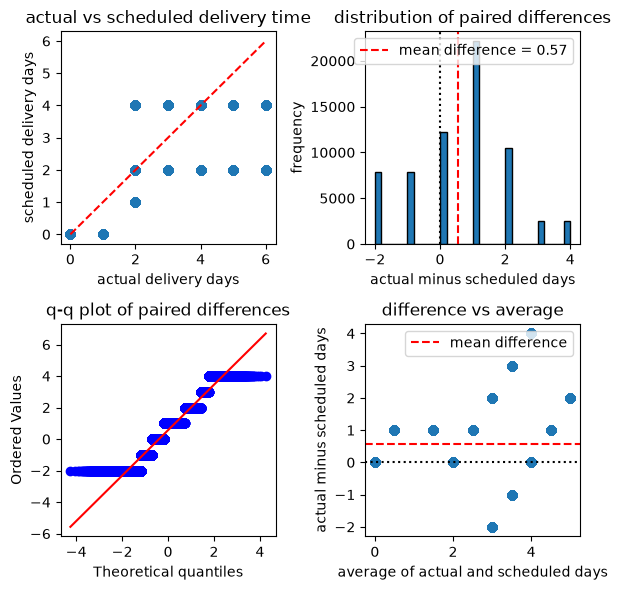

In [56]:
# calculate paired differences and pairwise averages
differences = actual_days - scheduled_days
averages = (actual_days + scheduled_days) / 2

# remove missing and infinite values
valid = np.isfinite(differences) & np.isfinite(averages)
differences = differences[valid]
averages = averages[valid]
actual = actual_days[valid]
scheduled = scheduled_days[valid]

fig, axes = plt.subplots(2, 2, figsize=(6, 6))

# 1. compare actual and scheduled delivery times
axes[0, 0].scatter(actual, scheduled, alpha=0.3)

min_val = min(actual.min(), scheduled.min())
max_val = max(actual.max(), scheduled.max())

# points on this line have identical actual and scheduled times
axes[0, 0].plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    color="red"
)

axes[0, 0].set_title("actual vs scheduled delivery time")
axes[0, 0].set_xlabel("actual delivery days")
axes[0, 0].set_ylabel("scheduled delivery days")


# 2. distribution of paired differences
axes[0, 1].hist(
    differences,
    bins=30,
    edgecolor="black"
)

axes[0, 1].axvline(
    differences.mean(),
    color="red",
    linestyle="--",
    label=f"mean difference = {differences.mean():.2f}"
)

axes[0, 1].axvline(0, color="black", linestyle=":")
axes[0, 1].set_title("distribution of paired differences")
axes[0, 1].set_xlabel("actual minus scheduled days")
axes[0, 1].set_ylabel("frequency")
axes[0, 1].legend()

# 3. normal q-q plot of paired differences
stats.probplot(
    differences,
    dist="norm",
    plot=axes[1, 0]
)

axes[1, 0].set_title("q-q plot of paired differences")

# 4. difference vs average delivery time
axes[1, 1].scatter(
    averages,
    differences,
    alpha=0.3
)

axes[1, 1].axhline(
    differences.mean(),
    color="red",
    linestyle="--",
    label="mean difference"
)

axes[1, 1].axhline(0, color="black", linestyle=":")
axes[1, 1].set_title("difference vs average")
axes[1, 1].set_xlabel("average of actual and scheduled days")
axes[1, 1].set_ylabel("actual minus scheduled days")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Plot summary
Actual vs scheduled:  
No specific shape is required; this plot is descriptive, and deviations from the diagonal show delivery delays or early deliveries.

Distribution of paired differences:  
Ideally roughly symmetric and bell-shaped, without severe outliers.

Q-Q plot:  
Points should fall approximately along the diagonal, without strong curvature or extreme deviations.

Difference vs average:  
Ideally no strong pattern or funnel shape, suggesting differences don't systematically change with delivery duration.

# Welch's t-test

Tests whether the means of two independent samples are significantly different without assuming equal variances.

Question:  
Do orders flagged as high risk for late delivery have significantly different average sales from orders not flagged as high risk?

The test statistic measures how many standard errors the difference between the two sample means is from zero, calculated as the difference between means divided by the standard error of that difference.

Formula:  
t = (mean_1 - mean_2) / sqrt((variance_1 / n_1) + (variance_2 / n_2))

## Paired vs Welch's
A paired t-test compares two related measurements from the same subjects, such as actual versus scheduled delivery time for each order, by testing whether the mean of the paired differences is zero.

Welch’s t-test compares the means of two independent groups, such as sales for high-risk versus low-risk orders, without assuming equal variances.

In [57]:
high_risk_sales = order_df.loc[
    order_df["Late_delivery_risk"] == 1,
    "Sales"
]

low_risk_sales = order_df.loc[
    order_df["Late_delivery_risk"] == 0,
    "Sales"
]

t_stat, p_value = stats.ttest_ind(
    high_risk_sales,
    low_risk_sales,
    equal_var=False
)

report_test(
    name="2. Welch's T-Test: Sales by Late-Delivery Risk",
    h0="Mean sales are equal between risk groups",
    h1="Mean sales differ between risk groups",
    statistic=t_stat,
    p_value=p_value
)

print(f"High-risk mean sales: {high_risk_sales.mean():.2f}")
print(f"Low-risk mean sales: {low_risk_sales.mean():.2f}")


2. Welch's T-Test: Sales by Late-Delivery Risk
----------------------------------------------------------------------
h0 Mean sales are equal between risk groups
h1 Mean sales differ between risk groups
test statistic -3.2917
p value 0.000996
decision reject h0
interpretation there is statistically significant evidence against the null hypothesis
High-risk mean sales: 192.37
Low-risk mean sales: 196.47


### Conclusion
We reject the null and conclude there is strong evidence that avg sales differ between high and low late-delivery risk groups.  
At a diff of roughly ~4, is this reasonable? More investigation is needed; the t-test is just one step towards a decision.

# Chi-square test of independence

Tests whether two categorical variables are associated or independent.

Question:  
Is shipping mode associated with late-delivery risk?

The test statistic measures how much the observed counts differ from the counts expected if the two variables were independent.

Formula:  
chi_square = sum((observed - expected)^2 / expected)

Null hypothesis (H0):  
Shipping mode and late-delivery risk are independent.

Alternative hypothesis (H1):  
Shipping mode and late-delivery risk are associated.

## Intuitively...
The chi-square test divides each squared difference by its expected count, so it measures deviations relative to what was expected, not just their raw magnitude.

## Formally...
Expected counts under H0:  
h0: p(a and b) = p(a) * p(b)  
expected count = (row total * column total) / grand total

In [58]:
contingency_table = pd.crosstab(
    order_df["Shipping Mode"],
    order_df["Late_delivery_risk"]
)

# dof = degrees of freedom = the number of independent values in a data set 
# that are free to vary when estimating a statistical parameter
chi2_stat, p_value, dof, expected = (
    stats.chi2_contingency(contingency_table)
)

report_test(
    name="3. Chi-Square Test: Shipping Mode vs Risk",
    h0="Shipping mode and late-delivery risk are independent",
    h1="Shipping mode and late-delivery risk are associated",
    statistic=chi2_stat,
    p_value=p_value
)

print("\nObserved counts:")
print(contingency_table)

print("\nExpected counts under H0:")
print(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)


3. Chi-Square Test: Shipping Mode vs Risk
----------------------------------------------------------------------
h0 Shipping mode and late-delivery risk are independent
h1 Shipping mode and late-delivery risk are associated
test statistic 13661.6746
p value 0.000000
decision reject h0
interpretation there is statistically significant evidence against the null hypothesis

Observed counts:
Late_delivery_risk      0      1
Shipping Mode                   
First Class           477   9602
Same Day             1923   1648
Second Class         2975   9803
Standard Class      24329  14995

Expected counts under H0:
Late_delivery_risk         0         1
Shipping Mode                         
First Class          4553.27   5525.73
Same Day             1613.23   1957.77
Second Class         5772.57   7005.43
Standard Class      17764.94  21559.06


## Chi-squared diagnostic plots

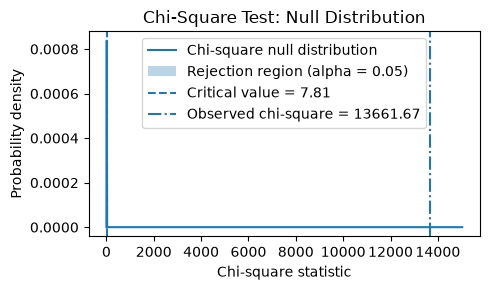

In [61]:
# Calculate the chi-square null distribution
alpha = 0.05

x_max = max(
    stats.chi2.ppf(0.999, dof),
    chi2_stat * 1.1
)

x = np.linspace(0, x_max, 1000)
y = stats.chi2.pdf(x, df=dof)

critical_value = stats.chi2.ppf(1 - alpha, df=dof)

# Plot the null distribution
plt.figure(figsize=(5, 3))
plt.plot(x, y, label="Chi-square null distribution")

# Shade the rejection region
plt.fill_between(
    x, y,
    where=(x >= critical_value),
    alpha=0.3,
    label=f"Rejection region (alpha = {alpha})"
)

# Mark the critical value and observed statistic
plt.axvline(
    critical_value,
    linestyle="--",
    label=f"Critical value = {critical_value:.2f}"
)
plt.axvline(
    chi2_stat,
    linestyle="-.",
    label=f"Observed chi-square = {chi2_stat:.2f}"
)

plt.title("Chi-Square Test: Null Distribution")
plt.xlabel("Chi-square statistic")
plt.ylabel("Probability density")
plt.legend()
plt.tight_layout()
plt.show()

### Recall...
These results support the connection we made earlier between shipping modes and late-delivery risk in the notebook:  
Data-Science-Portfolio/DataCo Smart Supply Chain for Big Data Analysis/01. Predicting late orders.ipynb > box plots towards the bottom

## Chi-square diagnostics
Observed vs expected counts

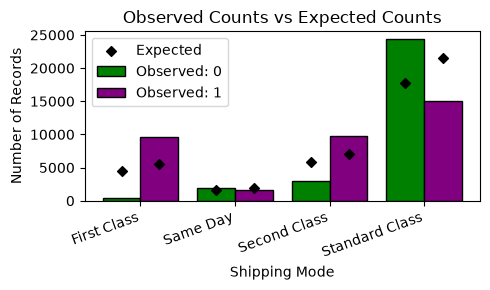


How to interpret it:
- If a bar is above its diamond, that combination occurs more often than expected under independence.
- If a bar is below its diamond, it occurs less often than expected.
- If bars are close to their diamonds across all combinations, the observed data are more consistent with independence.
Our chi-square test was highly significant, so shipping mode and late-delivery risk are associated in this dataset. This chart helps show which combinations contribute to that association.


The observed 0 and 1 represent the two values of Late_delivery_risk:
- 0 = The order was not flagged as at risk of late delivery.
- 1 = The order was flagged as at risk of late delivery.



In [68]:
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

observed = contingency_table.to_numpy()
expected_values = expected_df.to_numpy()

colors = ['green', 'purple', 'red', 'pink']

n_rows, n_cols = observed.shape
positions = np.arange(n_rows)
bar_width = 0.8 / n_cols

fig, ax = plt.subplots(figsize=(5, 3))

for j, category in enumerate(contingency_table.columns):
    offset = (j - (n_cols - 1) / 2) * bar_width

    ax.bar(
        positions + offset,
        observed[:, j],
        width=bar_width,
        label=f"Observed: {category}",
        color=colors[j],
        edgecolor="black",
        linewidth=1
    )

    ax.scatter(
        positions + offset,
        expected_values[:, j],
        marker="D",
        color="black",
        s=25,
        zorder=3,
        label="Expected" if j == 0 else None
    )

ax.set_xticks(positions)
ax.set_xticklabels(contingency_table.index, rotation=20, ha="right")
ax.set_title("Observed Counts vs Expected Counts")
ax.set_xlabel("Shipping Mode")
ax.set_ylabel("Number of Records")
ax.legend()
fig.tight_layout()
plt.show()

print("""
How to interpret it:
- If a bar is above its diamond, that combination occurs more often than expected under independence.
- If a bar is below its diamond, it occurs less often than expected.
- If bars are close to their diamonds across all combinations, the observed data are more consistent with independence.
Our chi-square test was highly significant, so shipping mode and late-delivery risk are associated in this dataset. This chart helps show which combinations contribute to that association.
""")

print("""
The observed 0 and 1 represent the two values of Late_delivery_risk:
- 0 = The order was not flagged as at risk of late delivery.
- 1 = The order was flagged as at risk of late delivery.
""")

### Conclusion
For the chi-square test, we care about how far the observed counts deviate from expected counts, regardless of direction.  
Above, only Same Day shows roughly equal observed/expected values.  
The large deviations between diamonds and bars supports our finding to reject the null, and conclude there is strong evidence to support a relationship between shipping mode and delivery risk.

# One-way ANOVA
##  vs. paired t-test...
Both tests compare means, but they are designed for different types of comparisons.

The paired t-test compares the means of two related measurements, while one-way ANOVA compares the means of three or more independent groups.

Question:
- Paired t-test: Is actual delivery time significantly different from scheduled delivery time for the same orders?
- One-way ANOVA: Does average actual delivery time differ across shipping modes?

The paired t-test calculates the differences between each pair of measurements and tests whether the mean difference is significantly different from zero.

One-way ANOVA compares variability between group means with variability within the groups to test whether at least one population mean differs.

Formulas:
- Paired t-test: t = mean_difference / (standard_deviation_of_differences / sqrt(n))
- One-way ANOVA: F = between-group variance / within-group variance

Key distinction:
One-way ANOVA is a natural extension of comparing means across groups, but it is not simply an extension of the paired t-test. It typically assumes independent groups, whereas the paired t-test explicitly accounts for related observations. For two independent groups, a t-test or one-way ANOVA can be used to compare means. For three or more independent groups, one-way ANOVA is the standard approach.

## vs. two-way ANOVA
One-way ANOVA asks: Does one categorical variable explain differences in the outcome?

Two-way ANOVA asks: Do two categorical variables explain differences in the outcome, and do they interact?

For our data:
- One-way: Does mean delivery time differ by shipping mode?
- Two-way: Does mean delivery time differ by shipping mode, by region, or by a combination of shipping mode and region?  
The F-statistic still compares explained variation against unexplained variation. Two-way ANOVA simply partitions the explained variation into separate effects.

In [72]:
shipping_groups = [
    group["Days for shipping (real)"].values
    for _, group in order_df.groupby("Shipping Mode")
]

shipping_modes = list(
    order_df["Shipping Mode"].unique()
)

f_stat, p_value = stats.f_oneway(
    *shipping_groups
)

report_test(
    name="4. One-Way ANOVA: Delivery Time by Shipping Mode",
    h0="Mean delivery time is equal across shipping modes",
    h1="At least one shipping mode has a different mean",
    statistic=f_stat,
    p_value=p_value
)

print("\nMean delivery time by shipping mode:")
print(
    order_df.groupby("Shipping Mode")[
        "Days for shipping (real)"
    ].mean().sort_values()
)


4. One-Way ANOVA: Delivery Time by Shipping Mode
----------------------------------------------------------------------
h0 Mean delivery time is equal across shipping modes
h1 At least one shipping mode has a different mean
test statistic 14161.9099
p value 0.000000
decision reject h0
interpretation there is statistically significant evidence against the null hypothesis

Mean delivery time by shipping mode:
Shipping Mode
Same Day          0.483618
First Class       2.000000
Standard Class    3.996898
Second Class      4.001565
Name: Days for shipping (real), dtype: float64


### Observe
One-way ANOVA tells us at least one shipping mode has a different mean, but which one?  
Notice that Standard and Second have nearly equal means, at 4 days.  

### Next steps
Run pairwise Welch's t-tests for all six shipping-mode pairs, then apply a Holm correction to the p-values to account for multiple comparisons. This allows unequal variances while controlling the family-wise false-positive rate.

In [76]:
from itertools import combinations
from scipy import stats
from statsmodels.stats.multitest import multipletests

# Run pairwise Welch's t-tests
results = []

for mode1, mode2 in combinations(
    order_df["Shipping Mode"].unique(), 2
):
    group1 = order_df.loc[
        order_df["Shipping Mode"] == mode1,
        "Days for shipping (real)"
    ]

    group2 = order_df.loc[
        order_df["Shipping Mode"] == mode2,
        "Days for shipping (real)"
    ]

    t_stat, p_value = stats.ttest_ind(
        group1, group2, equal_var=False
    )

    results.append({
        "Group 1": mode1,
        "Group 2": mode2,
        "Mean 1": group1.mean(),
        "Mean 2": group2.mean(),
        "Mean Difference": group1.mean() - group2.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    })

posthoc_df = pd.DataFrame(results)

# Adjust p-values for multiple comparisons
posthoc_df["Adjusted p-value"] = multipletests(
    posthoc_df["p-value"],
    method="holm"
)[1]

posthoc_df["Significant"] = (
    posthoc_df["Adjusted p-value"] < 0.05
)

print(posthoc_df.sort_values("Adjusted p-value").to_string(index=False))

/opt/anaconda3/envs/deep-learning/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/opt/anaconda3/envs/deep-learning/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/opt/anaconda3/envs/deep-learning/lib/python3.11/site-packages/scipy/stats/_axis_nan_policy.py:592: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


       Group 1      Group 2   Mean 1   Mean 2  Mean Difference  t-statistic  p-value  Adjusted p-value  Significant
Standard Class  First Class 3.996898 2.000000         1.996898   279.585429 0.000000          0.000000         True
Standard Class     Same Day 3.996898 0.483618         3.513280   319.433890 0.000000          0.000000         True
   First Class Second Class 2.000000 4.001565        -2.001565  -159.843843 0.000000          0.000000         True
   First Class     Same Day 2.000000 0.483618         1.516382   181.303397 0.000000          0.000000         True
  Second Class     Same Day 4.001565 0.483618         3.517947   233.621277 0.000000          0.000000         True
Standard Class Second Class 3.996898 4.001565        -0.004668    -0.323786 0.746103          0.746103        False


In [77]:
print(
    order_df.groupby("Shipping Mode")["Days for shipping (real)"]
    .agg(["count", "mean", "std", "nunique"])
)

                count      mean       std  nunique
Shipping Mode                                     
First Class     10079  2.000000  0.000000        1
Same Day         3571  0.483618  0.499802        2
Second Class    12778  4.001565  1.415485        5
Standard Class  39324  3.996898  1.416348        5


In [ ]:
raise apple

In [ ]:

import pandas as pd
import numpy as np

from pathlib import Path
from scipy import stats


# ============================================================
# LOAD DATA
# ============================================================

# Set this to the directory containing your CSV.
# Example:
# data_dir = Path("/Users/yourname/Desktop/DataCo")

DataCoSupplyChainDataset = pd.read_csv(
    data_dir / "DataCoSupplyChainDataset.csv",
    encoding="Latin-1",
    low_memory=False
)

df = DataCoSupplyChainDataset.copy()

print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns):,}")


# ============================================================
# PREPARE DATA
# ============================================================

numeric_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Late_delivery_risk",
    "Sales",
    "Order Item Quantity",
    "Order Item Discount"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

df = df.dropna(subset=numeric_columns)

# Actual delivery time minus scheduled delivery time.
# Positive = late; negative = early.
df["Delivery_Delay"] = (
    df["Days for shipping (real)"]
    - df["Days for shipment (scheduled)"]
)

# A binary indicator for whether the delivery was actually late.
df["Actually_Late"] = (
    df["Delivery_Delay"] > 0
).astype(int)

# Keep one row per order for order-level delivery tests.
# Shipping duration is generally an order-level measure.
order_df = df.drop_duplicates(
    subset=["Order Id"]
).copy()


# ============================================================
# HELPER FUNCTION
# ============================================================

ALPHA = 0.05


def report_test(
    name,
    h0,
    h1,
    statistic,
    p_value
):
    print("\n" + "=" * 70)
    print(name)
    print("-" * 70)

    print(f"H0: {h0}")
    print(f"H1: {h1}")

    print(f"Test statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6f}")

    if p_value < ALPHA:
        print("Decision: Reject H0.")
        print(
            "Interpretation: There is statistically significant "
            "evidence against the null hypothesis."
        )
    else:
        print("Decision: Fail to reject H0.")
        print(
            "Interpretation: There is insufficient evidence "
            "against the null hypothesis."
        )


# ============================================================
# 1. PAIRED T-TEST
#
# Question:
# Is actual delivery time significantly different from
# scheduled delivery time?
#
# Same order measured against its scheduled delivery duration.
# ============================================================

actual_days = order_df[
    "Days for shipping (real)"
]

scheduled_days = order_df[
    "Days for shipment (scheduled)"
]

t_stat, p_value = stats.ttest_rel(
    actual_days,
    scheduled_days
)

report_test(
    name="1. Paired T-Test: Actual vs Scheduled Delivery",
    h0="Mean actual delivery time equals mean scheduled time",
    h1="Mean actual delivery time differs from scheduled time",
    statistic=t_stat,
    p_value=p_value
)

print(f"Mean actual days: {actual_days.mean():.2f}")
print(f"Mean scheduled days: {scheduled_days.mean():.2f}")
print(
    f"Mean delay: "
    f"{(actual_days - scheduled_days).mean():.2f} days"
)


# ============================================================
# 2. WELCH TWO-SAMPLE T-TEST
#
# Question:
# Do sales differ between orders classified as high
# late-delivery risk and low late-delivery risk?
#
# Independent groups, unequal variances allowed.
# ============================================================

high_risk_sales = df.loc[
    df["Late_delivery_risk"] == 1,
    "Sales"
]

low_risk_sales = df.loc[
    df["Late_delivery_risk"] == 0,
    "Sales"
]

t_stat, p_value = stats.ttest_ind(
    high_risk_sales,
    low_risk_sales,
    equal_var=False
)

report_test(
    name="2. Welch T-Test: Sales by Late-Delivery Risk",
    h0="Mean sales are equal between risk groups",
    h1="Mean sales differ between risk groups",
    statistic=t_stat,
    p_value=p_value
)

print(f"High-risk mean sales: {high_risk_sales.mean():.2f}")
print(f"Low-risk mean sales: {low_risk_sales.mean():.2f}")


# ============================================================
# 3. CHI-SQUARE TEST OF INDEPENDENCE
#
# Question:
# Is shipping mode associated with late-delivery risk?
#
# Both variables are categorical.
# ============================================================

contingency_table = pd.crosstab(
    df["Shipping Mode"],
    df["Late_delivery_risk"]
)

chi2_stat, p_value, dof, expected = (
    stats.chi2_contingency(contingency_table)
)

report_test(
    name="3. Chi-Square Test: Shipping Mode vs Risk",
    h0="Shipping mode and late-delivery risk are independent",
    h1="Shipping mode and late-delivery risk are associated",
    statistic=chi2_stat,
    p_value=p_value
)

print("\nObserved counts:")
print(contingency_table)

print("\nExpected counts under H0:")
print(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)


# ============================================================
# 4. ONE-WAY ANOVA
#
# Question:
# Does average actual delivery time differ by shipping mode?
#
# Compares means across 3+ independent groups.
# ============================================================

shipping_groups = [
    group["Days for shipping (real)"].values
    for _, group in order_df.groupby("Shipping Mode")
]

shipping_modes = list(
    order_df["Shipping Mode"].unique()
)

f_stat, p_value = stats.f_oneway(
    *shipping_groups
)

report_test(
    name="4. One-Way ANOVA: Delivery Time by Shipping Mode",
    h0="Mean delivery time is equal across shipping modes",
    h1="At least one shipping mode has a different mean",
    statistic=f_stat,
    p_value=p_value
)

print("\nMean delivery time by shipping mode:")
print(
    order_df.groupby("Shipping Mode")[
        "Days for shipping (real)"
    ].mean().sort_values()
)


# ============================================================
# 5. TWO-PROPORTION Z-TEST
#
# Question:
# Is the actual late-delivery rate different between
# Standard Class and Second Class?
#
# Compares proportions between two independent groups.
# ============================================================

from statsmodels.stats.proportion import proportions_ztest

standard = order_df[
    order_df["Shipping Mode"] == "Standard Class"
]

second = order_df[
    order_df["Shipping Mode"] == "Second Class"
]

late_standard = standard["Actually_Late"].sum()
total_standard = len(standard)

late_second = second["Actually_Late"].sum()
total_second = len(second)

successes = np.array([
    late_standard,
    late_second
])

observations = np.array([
    total_standard,
    total_second
])

z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=observations,
    alternative="two-sided"
)

report_test(
    name="5. Two-Proportion Z-Test: Actual Late Rates",
    h0="Actual late-delivery rates are equal",
    h1="Actual late-delivery rates differ",
    statistic=z_stat,
    p_value=p_value
)

print(
    f"Standard Class late rate: "
    f"{late_standard / total_standard:.2%}"
)

print(
    f"Second Class late rate: "
    f"{late_second / total_second:.2%}"
)
